In [109]:
import numpy as np
import pandas as pd

In [166]:
# Line styles for dimensions
linestyle_map = {
    1: "-.",
    2: "--",
    3: ":",
}

# Shorter legend labels
bc_label_map = {
    "PERIODIC": "Periodic",
    "BOUNCE_BACK": "Bounce-back",
    "SIMPLE_SLIP": "Simple slip",
}


marker_map = {
    "PERIODIC": "d",        # square
    "SIMPLE_SLIP": "^",     # triangle
    "BOUNCE_BACK": "o",     # circle (keep default)
}

palette = {
    "PERIODIC": "tab:blue",
    "BOUNCE_BACK": "tab:orange",
    "SIMPLE_SLIP": "tab:green",
}

legent_font_size = 16
legent_title_font_size = 17
figsize = (12, 7)

# Create legend

In [188]:
import matplotlib.pyplot as plt

def plot_legend_only(df, save_path=None):
    """
    Create a standalone legend figure for dimension and boundary condition.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain columns:
        - dimension
        - boundary_condition
    save_path : str, optional
        If provided, saves the legend to file.
    """

    data = df.copy()

    fig, ax = plt.subplots(figsize=(8, 2))

    # Create dummy lines for legend
    for (d, bc), _ in data.groupby(["dimension", "boundary_condition"]):
        ax.plot(
            [], [],
            marker=marker_map[bc],
            linestyle=linestyle_map[d],
            color=palette.get(bc, None),
            linewidth=2,
            markersize=6,
            label=f"d={d}, {bc_label_map[bc]}"
        )

    # Hide axes completely
    ax.axis("off")

    # Create legend
    fig.legend(
        title="Dimension and boundary condition",
        loc="center",
        ncol=3,
        frameon=True,
        fontsize=legent_font_size,
        title_fontsize=legent_title_font_size
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


# Grid size scaling

In [167]:
grid_pd = pd.read_csv('./output/grid_scalling_results.csv')
grid_pd.head()

,dimension,m,N,grid_size,boundary_condition,iterations,num_qubits,depth,gate_count,cnot_total,x_count,h_count,u3_count,cx_count,t_count,t_dg_count,p_count
0,1,1,2,2,PERIODIC,0,1,0,0,0,0,0,0,0,0,0,0
1,1,1,2,2,PERIODIC,1,6,239,402,156,4,62,2,156,42,56,80
2,1,1,2,2,PERIODIC,5,6,1187,2090,780,20,318,2,780,210,280,480
3,1,2,4,4,PERIODIC,0,2,0,0,0,0,0,0,0,0,0,0
4,1,2,4,4,PERIODIC,1,7,392,683,280,4,90,2,280,66,88,153


In [168]:
grid_pd.columns

Index(['dimension', 'm', 'N', 'grid_size', 'boundary_condition', 'iterations',
       'num_qubits', 'depth', 'gate_count', 'cnot_total', 'x_count', 'h_count',
       'u3_count', 'cx_count', 't_count', 't_dg_count', 'p_count'],
      dtype='str')

In [169]:
df = prepare_qubit_scaling_df(grid_pd, iterations=10)
df.head(60)

,dimension,boundary_condition,m,num_qubits


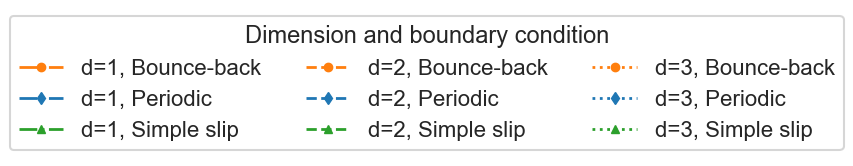

In [189]:
plot_legend_only(grid_pd, save_path="scaling_legend.pdf")

In [190]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

sns.set_theme(style="whitegrid", context="talk")

def plot_all_qubit_lines_pretty(
    df,
    iterations=5,
    x_metric="m",           # ✅ NEW
    y_metric="num_qubits",  # ✅ existing
    save_path=None,
    y_log_scale=False,
    show_legend=True,
):
    # Filter logic
    if x_metric == "m":
        data = df[df["iterations"] == iterations].copy()
    else:
        data = df.copy()

    data = data.sort_values(["dimension", "boundary_condition", x_metric])

    fig, ax = plt.subplots(figsize=figsize)

    for (d, bc), subset in data.groupby(["dimension", "boundary_condition"]):
        subset = subset.sort_values(x_metric)

        ax.plot(
            subset[x_metric],             # ✅ dynamic x
            subset[y_metric],             # ✅ dynamic y
            marker=marker_map[bc],
            linestyle=linestyle_map[d],
            color=palette.get(bc, None),
            linewidth=2,
            markersize=6,
            label=f"d={d}, {bc_label_map[bc]}"
        )

    # ---- X-axis formatting ----
    unique_x = sorted(data[x_metric].unique())
    ax.set_xticks(unique_x)

    # Pretty formatting depending on axis type
    if x_metric == "m":
        ax.set_xticklabels([rf"$2^{{{m}}}$" for m in unique_x])
        ax.set_xlabel(r"Domain side size $N$")

    elif x_metric == "iterations":
        if y_log_scale:
            ax.set_yscale("log", base=2)        
        ax.set_xscale("log", base=2)   # ✅ log2 axis
        ax.set_xticks(unique_x)
        ax.set_xticklabels([str(int(i)) for i in unique_x])

        ax.set_xlabel(r"Number of iterations $T$")

    else:
        ax.set_xlabel(x_metric.replace("_", " ").title())

    # ---- Y-axis formatting ----
    if y_metric == "num_qubits":
        ax.set_ylabel("Number of qubits")

    elif y_metric == "depth":
        ax.set_ylabel("Circuit depth")

    elif y_metric == "gate_count":
        ax.set_ylabel("Gate count")

    elif y_metric == "depth_per_iteration":
        ax.set_ylabel("Depth per iteration")

    elif y_metric == "gate_count_per_iteration":
        ax.set_ylabel("Gate count per iteration")

    else:
        ax.set_ylabel(y_metric.replace("_", " ").title())

    if show_legend:
        # ---- Legend below ----
        ax.legend(
            title="Dimension and boundary condition",
            loc="upper center",
            bbox_to_anchor=(0.5, -0.22),
            ncol=3,
            frameon=True,
            fontsize=legent_font_size,
            title_fontsize=legent_title_font_size
        )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.28)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


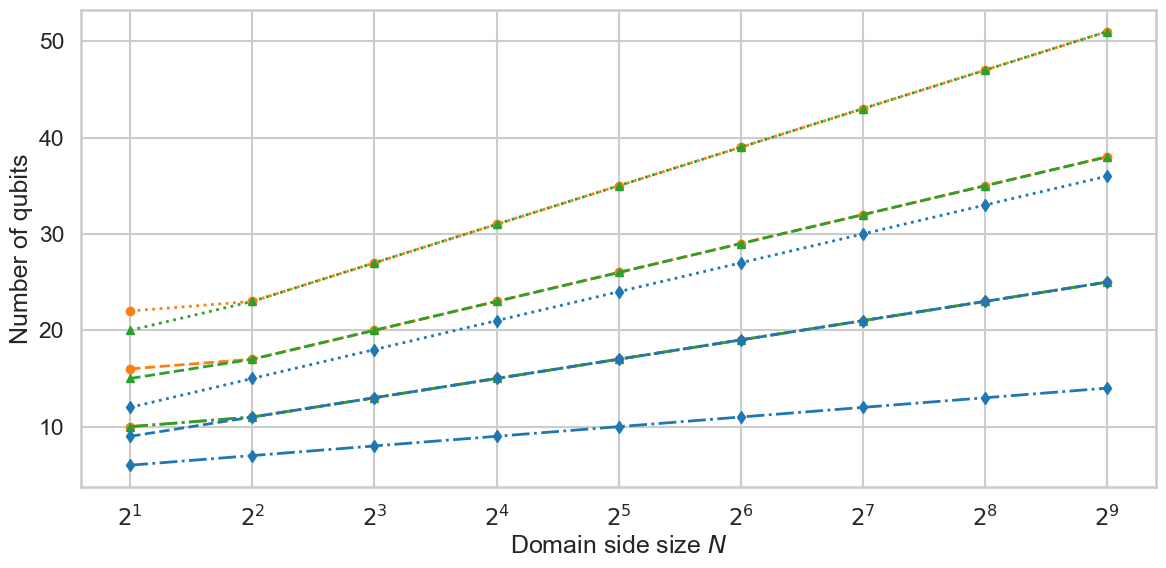

In [179]:
plot_all_qubit_lines_pretty(grid_pd, iterations=5, save_path="scaling_grid_size_qubits.pdf", show_legend=False)

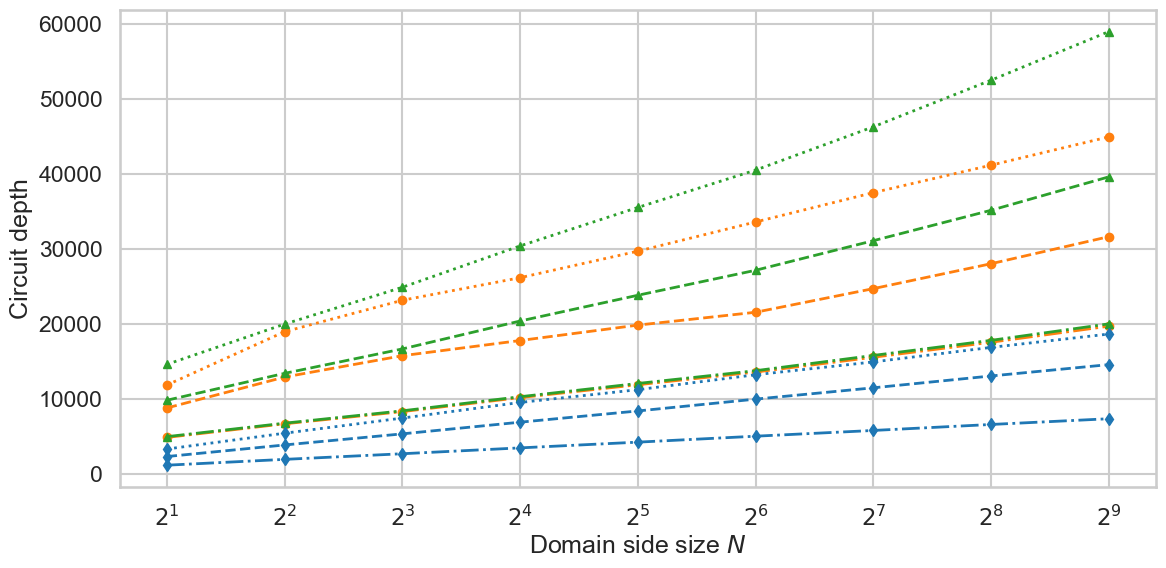

In [180]:
plot_all_qubit_lines_pretty(grid_pd, iterations=5, y_metric='depth', save_path="scaling_grid_size_depth.pdf", show_legend=False)

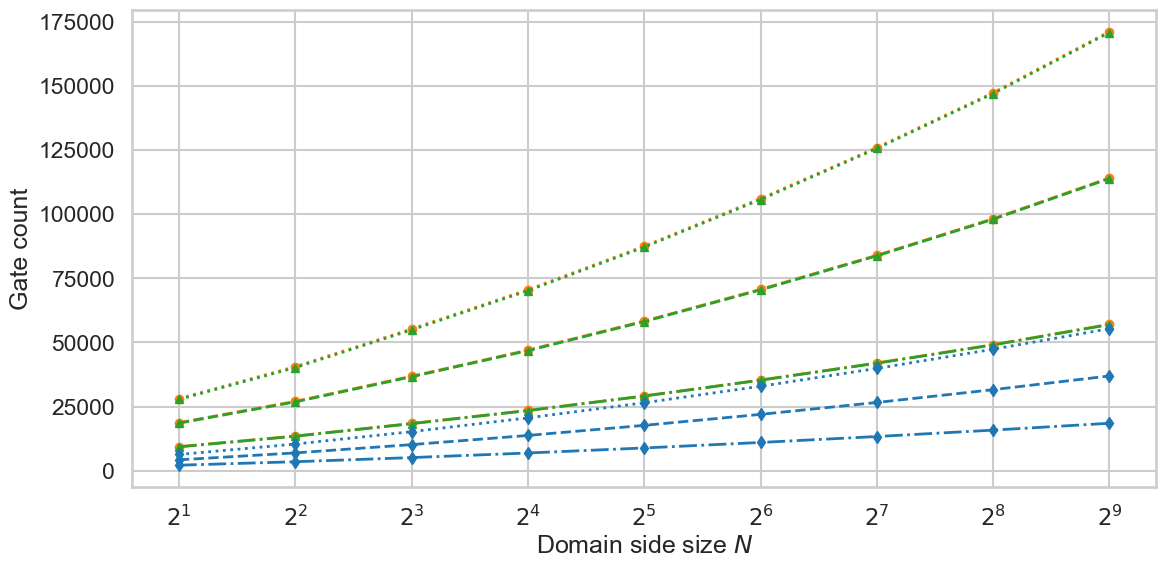

In [181]:
plot_all_qubit_lines_pretty(grid_pd, iterations=5, y_metric='gate_count', save_path="scaling_grid_size_gate_count.pdf", show_legend=False)

# Time scaling

In [174]:
time_pd = pd.read_csv('./output/time_scalling_results.csv')
time_pd.head()

,dimension,m,N,grid_size,boundary_condition,iterations,num_qubits,depth,gate_count,cnot_total,x_count,h_count,u3_count,cx_count,t_count,t_dg_count,p_count
0,1,5,32,32,PERIODIC,1,10,842,1724,784,4,174,2,784,138,184,438
1,1,5,32,32,PERIODIC,2,10,1696,3498,1596,8,350,2,1596,276,368,898
2,1,5,32,32,PERIODIC,4,10,3404,7046,3220,16,702,2,3220,552,736,1818
3,1,5,32,32,PERIODIC,8,10,6820,14142,6468,32,1406,2,6468,1104,1472,3658
4,1,5,32,32,PERIODIC,16,10,13652,28334,12964,64,2814,2,12964,2208,2944,7338


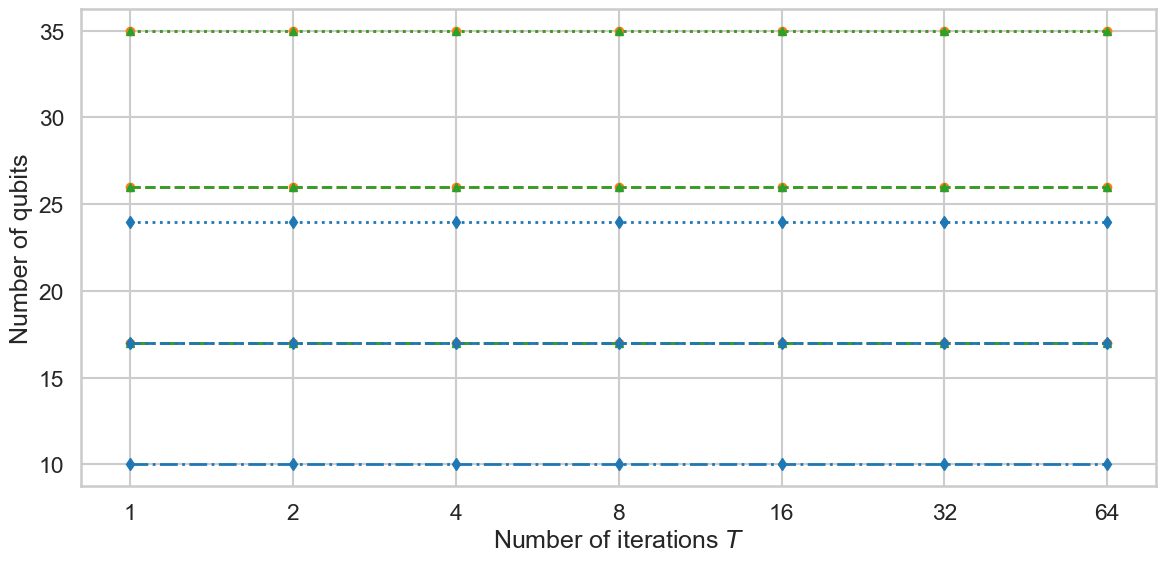

In [182]:
plot_all_qubit_lines_pretty(time_pd, iterations=5, x_metric='iterations', y_metric='num_qubits', save_path="scaling_time_qubits.pdf", show_legend=False)

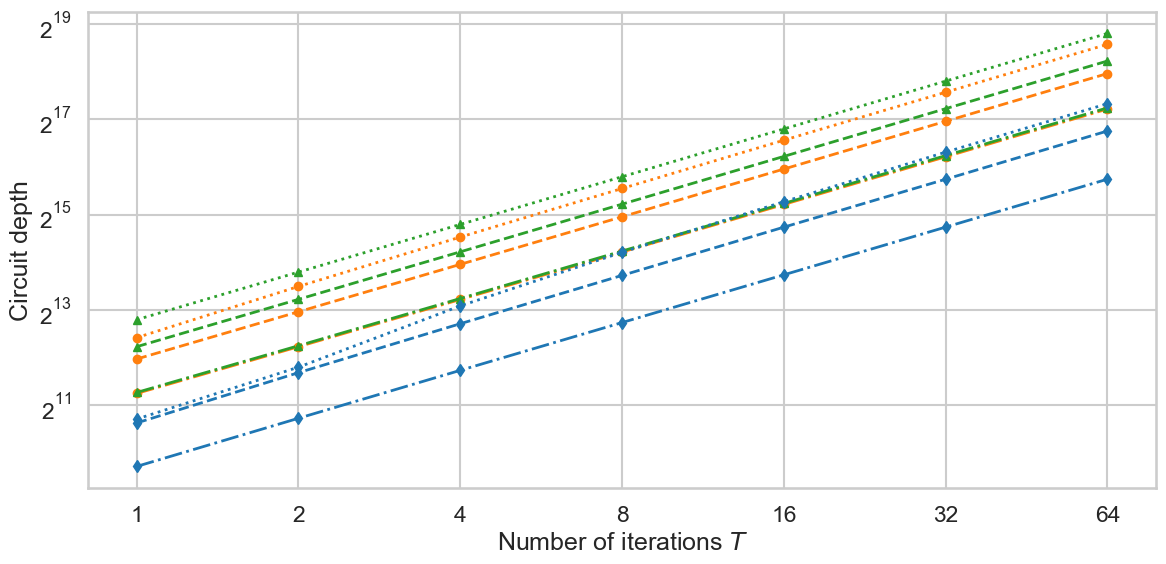

In [191]:
plot_all_qubit_lines_pretty(time_pd, iterations=5, x_metric='iterations', y_metric='depth', y_log_scale=True, save_path="scaling_time_depth.pdf", show_legend=False)